In [2]:
import numpy as np  # numpy - numerical calculations
import pandas as pd # pandas - data analysis and manipulation(loads,cleans and analyses data)
import matplotlib as plt  # matplotlib - data visualization
import seaborn as sns  # seaborn- statistical data visualization
df = pd.read_csv("archive/WA_Fn-UseC_-Telco-Customer-Churn.csv")


1. UNDERSTANDING DATA

In [3]:
# for inspecting the first 5 rows of the dataset
df.head()  # for inspecting the first 5 rows of the dataset

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# inspecting the last 5 rows of the dataset
df.tail()  

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [5]:
#checking dataset dimensions
print("Shape of the dataset: ", df.shape) #(rows, columns)
print("Number of customers in the dataset: ", df.shape[0])
print("Number of columns in the dataset: ", df.shape[1]) 

Shape of the dataset:  (7043, 21)
Number of customers in the dataset:  7043
Number of columns in the dataset:  21


In [6]:
# Inspecting data types and missing values in the dataset
df.info()  # provides a concise summary of the DataFrame, including the data types and non-null values for each column

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [7]:
# checking for null values in the dataset
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [8]:
#checking for duplicate rows in the dataset
print("Duplicate roows in the dataset: ", df.duplicated().sum())


Duplicate roows in the dataset:  0


In [9]:
# Inspecting column names
print(df.columns)  # for inspecting the column names of the dataset

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')


In [10]:
# Customers who churned vs those who stayed
print(df['Churn'].value_counts())  # for inspecting the distribution of values in the 'Churn' column

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [11]:
# Overall churn percentage
churn_percentage = (df['Churn'].value_counts(normalize=True) * 100).round(2)
print("Churn Percentage:\n", churn_percentage)

Churn Percentage:
 Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


2. DATA CLEANING

In [12]:
df_clean = df.copy() #.copy()- creates a copy of the original DataFrame to avoid modifying it directly.

In [13]:
# Investigateing missing values in the dataset
print(df_clean.isnull().sum)

<bound method DataFrame.sum of       customerID  gender  SeniorCitizen  Partner  Dependents  tenure  \
0          False   False          False    False       False   False   
1          False   False          False    False       False   False   
2          False   False          False    False       False   False   
3          False   False          False    False       False   False   
4          False   False          False    False       False   False   
...          ...     ...            ...      ...         ...     ...   
7038       False   False          False    False       False   False   
7039       False   False          False    False       False   False   
7040       False   False          False    False       False   False   
7041       False   False          False    False       False   False   
7042       False   False          False    False       False   False   

      PhoneService  MultipleLines  InternetService  OnlineSecurity  ...  \
0            False          F

In [14]:
# Inspecting 'TotalCharges' column
print(df_clean['TotalCharges'].head(10))  # inspecting the first 10 rows of the 'TotalCharges' column 
print(df_clean['TotalCharges'].dtype) # checking the data type of the 'TotalCharges' column

0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: str
str


In [15]:
# counting the number of blank values in the 'TotalCharges' column
blank_charges=df_clean['TotalCharges'].astype(str).str.strip().eq("").sum() 
print("Total blank values in TotalCharges: ", blank_charges) 

Total blank values in TotalCharges:  11


In [16]:
# Converting 'TotalCharges' column fron str to numeric
df_clean['TotalCharges']=pd.to_numeric(df_clean['TotalCharges'], errors='coerce')

# confirming chenge in data type of 'TotalCharges' column
print(df_clean["TotalCharges"].dtype)
print(df_clean.isnull().sum())

float64
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [17]:
# removing null values from the dataset
df_clean=df_clean.dropna(subset=["TotalCharges"]).copy()
print("Rows remaining",len(df_clean))
print("Missing TotalCharges:", df_clean["TotalCharges"].isnull().sum())

Rows remaining 7032
Missing TotalCharges: 0


CONNECTING PYTHON WITH PostgreSQL

In [18]:
#installation of python database libraries
%pip install sqlalchemy "psycopg[binary]"


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: C:\Users\User\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [19]:
# verifying wether installation was successful
import pandas as pd
import sqlalchemy
import psycopg

print("panda version: ", pd.__version__)
print("SQLAlchemy version: ",sqlalchemy.__version__)
print("Psycops version: ",psycopg.__version__)


from sqlalchemy import create_engine,text

panda version:  3.0.6
SQLAlchemy version:  2.1.4
Psycops version:  3.3.6


In [20]:
#creating connection to notebook
import os
from getpass import getpass
from sqlalchemy import create_engine, text
from sqlalchemy.engine import url
from sqlalchemy import create_engine, text, URL
#database connection setting
db_user=input("PostgreSQL username: ")
db_password=getpass("PostgreSQL password: ")
db_host="localhost"
db_port=5432
db_name="Customer_churn"

# Building database connection url safely
# Building database connection url safely
connect_url = URL.create(
    drivername="postgresql+psycopg",
    username=db_user,
    password=db_password,
    host=db_host,
    port=db_port,
    database=db_name,
)

# creating sqlalchemy engine
engine = create_engine(connect_url)
print("Database engine created successfully")
#creating sqlalchemy engine
engine=create_engine(connect_url)
print("Database engine created successfully")


Database engine created successfully
Database engine created successfully


In [21]:
# testing connection
with engine.connect() as connection:
    result = connection.execute(
        text("SELECT current_database(), current_user;")
    )
    print(result.fetchone())
    

('Customer_churn', 'postgres')


In [22]:
#check dataframe
print("Available dataframes")
print([
    name
    for name,obj in globals().items()
    if isinstance(obj, pd.DataFrame)]
      )

Available dataframes
['_', '__', 'df', '_3', '_4', 'df_clean']


In [23]:
#uploading dataset to sql

df.to_sql(
    name="customers",
    con=engine,
    if_exists="replace",
    index=False
)   

-1

In [24]:
# Verifying data
with engine.connect()as connection:  # engine.connect- pens connection to postgreSQL
    result=connection.execute(
        text("select count(*) from customers;")
        )
    total_customers=result.scalar()

    print("Rows stored in postgreSQL: ", total_customers)
    print("Rows in original DataFrame: ", len(df))

Rows stored in postgreSQL:  7043
Rows in original DataFrame:  7043


In [25]:
# inspecting first 5 columns
with engine.connect()as connection:
    sample=pd.read_sql(
        text("select * from customers limit 5;"),
        connection
        )
    print("Column names:")
    print(sample.columns.tolist())
    display(sample)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Loading complete dataset to python

In [26]:
print("Colunm names: ")
print(df.columns.tolist())
print("\nData types: ")
print(df.dtypes)

Colunm names: 
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types: 
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


ANALYZING AND VISUALZING
1. Clculating churn rate

In [27]:
churn_summary = pd.read_sql(
    text("""
        SELECT
            "Churn" AS churn_status,
            COUNT(*) AS customer_count,
            ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS churn_percentage
        FROM customers
        GROUP BY "Churn"
        ORDER BY customer_count DESC
    """),
    con=engine
)

display(churn_summary)

,churn_status,customer_count,churn_percentage
0,No,5174,73.46
1,Yes,1869,26.54


Turning sqlresults to python chart

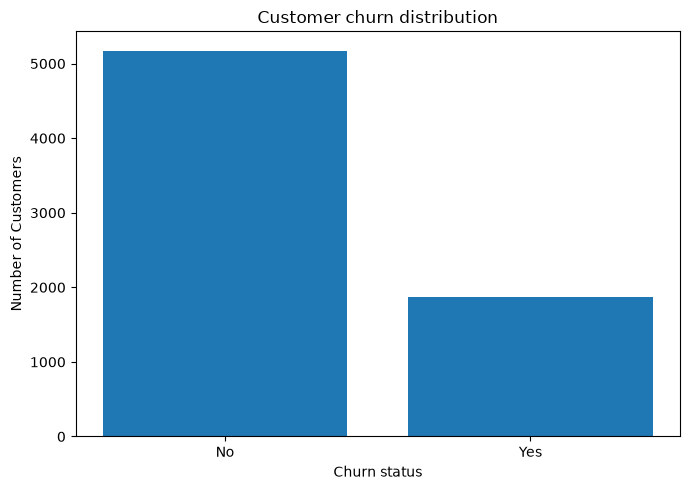

In [28]:
import matplotlib.pyplot as plt
plt.figure(figsize=(7,5))
plt.bar(
    churn_summary["churn_status"].astype(str),
    churn_summary["customer_count"],
)
plt.title("Customer churn distribution")
plt.xlabel("Churn status")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

Does contract type affect churn

In [29]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [30]:
# Calculating actual churn rate
contract_churn = pd.read_sql(
    text("""
        SELECT
            "Contract" AS contract_type,
            "Churn" AS churn_status,
            COUNT(*) AS customer_count
        FROM customers
        GROUP BY "Contract", "Churn"
        ORDER BY "Contract", "Churn"
    """),
    con=engine
)

display(contract_churn)


,contract_type,churn_status,customer_count
0,Month-to-month,No,2220
1,Month-to-month,Yes,1655
2,One year,No,1307
3,One year,Yes,166
4,Two year,No,1647
5,Two year,Yes,48


In [31]:
#Calculating churn rates by contract type
contract_rates = pd.read_sql(
    text("""
        SELECT
            "Contract" AS contract_type,
            COUNT(*) AS total_customers,
            COUNT(*) FILTER (WHERE "Churn" = 'Yes') AS churned_customers,
            ROUND(
                100.0 * COUNT(*) FILTER (WHERE "Churn" = 'Yes') / COUNT(*),
                2
            ) AS churn_rate_percent
        FROM customers
        GROUP BY "Contract"
        ORDER BY churn_rate_percent
    """),
    con=engine
)
display(contract_rates)

,contract_type,total_customers,churned_customers,churn_rate_percent
0,Two year,1695,48,2.83
1,One year,1473,166,11.27
2,Month-to-month,3875,1655,42.71


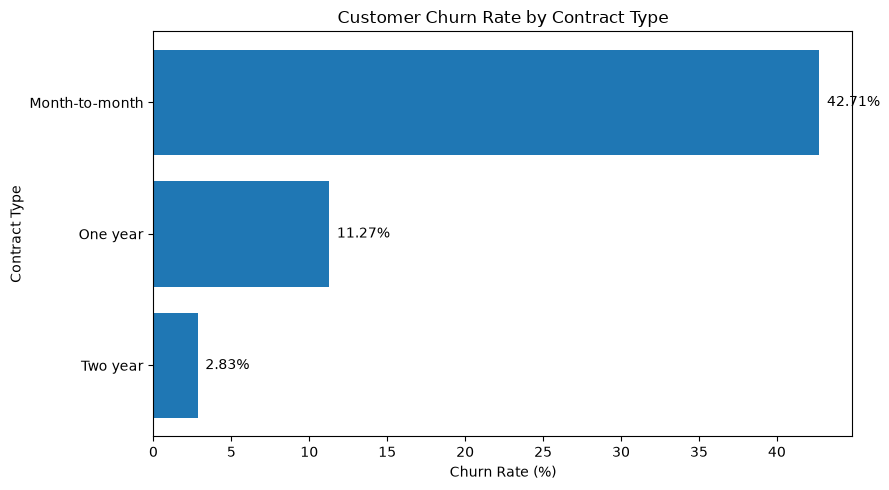

In [32]:
import matplotlib.pyplot as plt
# sort contract types (ascending)
plt_data = contract_rates.sort_values("churn_rate_percent")
# creating chart
plt.figure(figsize=(9, 5))
plt.barh(
    plt_data["contract_type"],
    plt_data["churn_rate_percent"]
)
plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Contract Type")

# Display % at the end of each bar
for position, value in enumerate(plt_data["churn_rate_percent"]):
    plt.text(value + 0.5, position, f"{value:.2f}%", va="center")

plt.tight_layout()
plt.show()


Are customers with hirgher monthly chrges more likely to churn?

In [33]:
# Analyze monthly charges and customer churn
#calculating average mothly charges
charges_analysis = pd.read_sql(
    text("""
        SELECT
            "Churn",
            COUNT(*) AS total_customers,
            ROUND(AVG("MonthlyCharges")::numeric, 2) AS average_monthly_charges,
            ROUND(MIN("MonthlyCharges")::numeric, 2) AS minimum_monthly_charges,
            ROUND(MAX("MonthlyCharges")::numeric, 2) AS maximum_monthly_charges
        FROM customers
        GROUP BY "Churn"
        ORDER BY "Churn"
    """),
    con=engine
)
display(charges_analysis)

,Churn,total_customers,average_monthly_charges,minimum_monthly_charges,maximum_monthly_charges
0,No,5174,61.27,18.25,118.75
1,Yes,1869,74.44,18.85,118.35


visualizing results

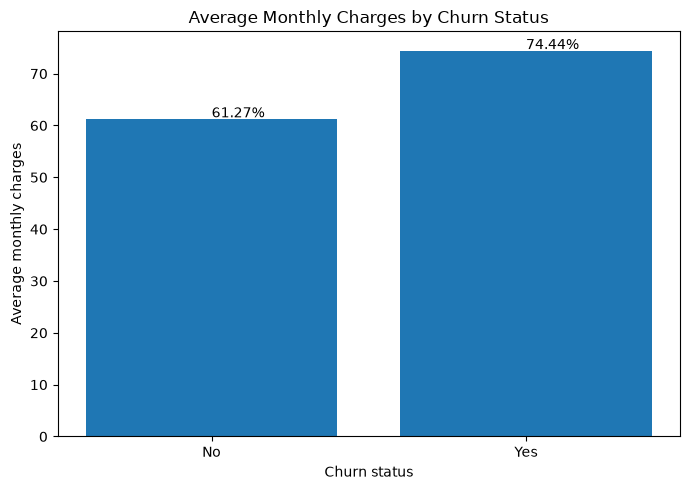

In [34]:
import matplotlib.pyplot as plt
plt.figure(figsize=(7,5))

plt.bar(
    charges_analysis["Churn"].astype(str),
    charges_analysis["average_monthly_charges"]
)
plt.title("Average Monthly Charges by Churn Status")
plt.xlabel("Churn status")
plt.ylabel("Average monthly charges")

for position, value in enumerate(charges_analysis["average_monthly_charges"]):
    plt.text(position,value + 1,  f"{value:.2f}%", va="center")

plt.tight_layout()
plt.show()

Analyzing customer tenure and churn

In [35]:
# calculating average tenure
tenure_analysis = pd.read_sql(
    text("""
        SELECT"Churn",
        COUNT(*) AS total_customers,
            ROUND(AVG("tenure"), 2) AS average_tenure_months,
            ROUND(MIN("tenure"), 2) AS minimum_tenure_months,
            ROUND(MAX("tenure"), 2) AS maximum_tenure_months
        FROM customers
        GROUP BY "Churn"
        ORDER BY "Churn"
    """),
    con=engine
)
display(tenure_analysis)

,Churn,total_customers,average_tenure_months,minimum_tenure_months,maximum_tenure_months
0,No,5174,37.57,0.0,72.0
1,Yes,1869,17.98,1.0,72.0


visualize results

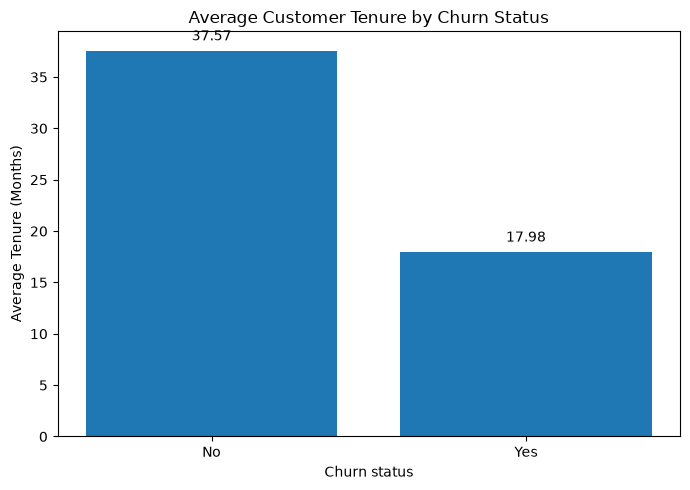

In [36]:

import matplotlib.pyplot as plt
plt.figure(figsize=(7,5))

plt.bar(
    tenure_analysis["Churn"].astype(str),
    tenure_analysis["average_tenure_months"]
)
plt.title("Average Customer Tenure by Churn Status")
plt.xlabel("Churn status")
plt.ylabel("Average Tenure (Months)")

for position, value in enumerate(tenure_analysis["average_tenure_months"]):
    plt.text(position, value + 1, f"{value:.2f}", ha="center")

plt.tight_layout()
plt.show()


Identify customers who are likely to churn


In [37]:

tenure_churn = pd.read_sql(
    text("""
        SELECT
            CASE
                WHEN "tenure" <= 12 THEN '0-12 months'
                WHEN "tenure" <= 24 THEN '13-24 months'
                WHEN "tenure" <= 48 THEN '25-48 months'
                ELSE '49-72 months'
            END AS tenure_group,

            COUNT(*) AS total_customers,

            COUNT(*)
             FILTER (WHERE "Churn" = 'Yes') AS churned_customers,

            ROUND(100.0 * COUNT(*) FILTER ( WHERE "Churn" = 'Yes') / COUNT(*),2) AS churn_rate_percent

        FROM customers

        GROUP BY
            CASE
                WHEN "tenure" <= 12 THEN '0-12 months'
                WHEN "tenure" <= 24 THEN '13-24 months'
                WHEN "tenure" <= 48 THEN '25-48 months'
                ELSE '49-72 months'
            END

        ORDER BY MIN("tenure");
    """),
    engine
)

display(tenure_churn)


,tenure_group,total_customers,churned_customers,churn_rate_percent
0,0-12 months,2186,1037,47.44
1,13-24 months,1024,294,28.71
2,25-48 months,1594,325,20.39
3,49-72 months,2239,213,9.51


visualizing result

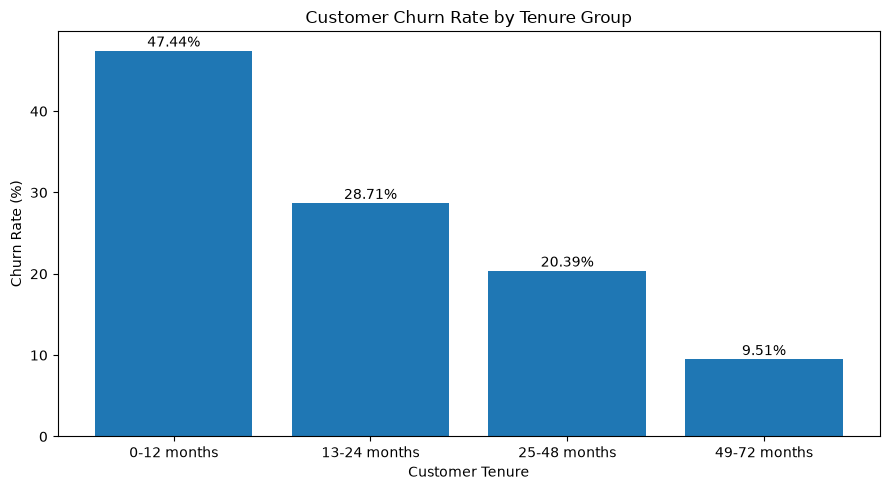

In [38]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    tenure_churn["tenure_group"],
    tenure_churn["churn_rate_percent"]
)

plt.title("Customer Churn Rate by Tenure Group")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")

for position, value in enumerate(tenure_churn["churn_rate_percent"]):
    plt.text(position, value + 0.5, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()


insights
1. newer customers are the hirghest risk group - 47.44%
2. churn rtes decrease across the tenure groups
3. early retention deserves attention

Analyzing internet service and customer churn

In [40]:

internet_churn = pd.read_sql(
    text("""
        SELECT
            "InternetService",
            COUNT(*) AS total_customers,

            COUNT(*) FILTER (WHERE "Churn" = 'Yes') AS churned_customers,

            ROUND(100.0 * COUNT(*) FILTER (WHERE "Churn" = 'Yes') / COUNT(*),2) 
            AS churn_rate_percent

        FROM customers

        GROUP BY "InternetService"

        ORDER BY churn_rate_percent DESC;
    """),
    engine
)

display(internet_churn)


,InternetService,total_customers,churned_customers,churn_rate_percent
0,Fiber optic,3096,1297,41.89
1,DSL,2421,459,18.96
2,No,1526,113,7.40


visualize results

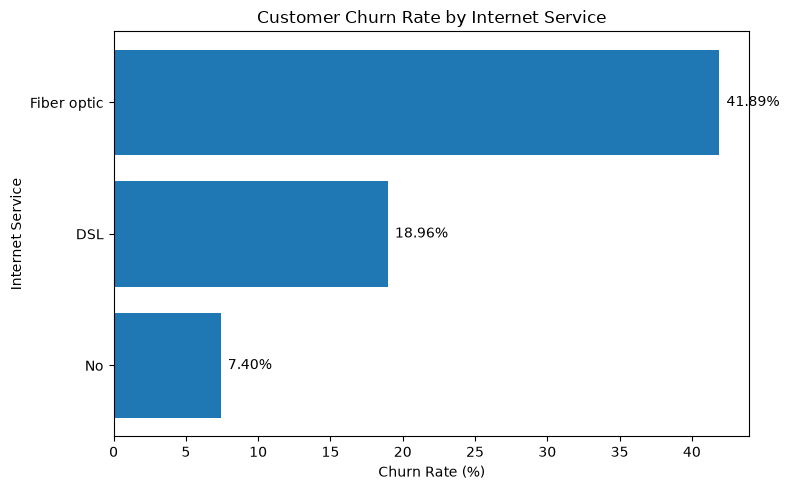

In [41]:

import matplotlib.pyplot as plt

plot_data = internet_churn.sort_values("churn_rate_percent")

plt.figure(figsize=(8, 5))

plt.barh(
    plot_data["InternetService"].astype(str),
    plot_data["churn_rate_percent"]
)

plt.title("Customer Churn Rate by Internet Service")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Internet Service")

for position, value in enumerate(plot_data["churn_rate_percent"]):
    plt.text(value + 0.5, position, f"{value:.2f}%", va="center")

plt.tight_layout()
plt.show()


Analyze churn by contract type

In [42]:

contract_churn = pd.read_sql(
    text("""
        SELECT
            "Contract",
            COUNT(*) AS total_customers,
            SUM(
                CASE
                    WHEN "Churn" = 'Yes' THEN 1
                    ELSE 0
                END
            ) AS churned_customers,
            ROUND(100.0 * SUM(
                    CASE
                        WHEN "Churn" = 'Yes' THEN 1
                        ELSE 0
                    END
                ) / COUNT(*),2) AS churn_rate_percent
        FROM customers
        GROUP BY "Contract"
        ORDER BY churn_rate_percent DESC;
    """),
    con=engine
)

display(contract_churn)


,Contract,total_customers,churned_customers,churn_rate_percent
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


visualize results

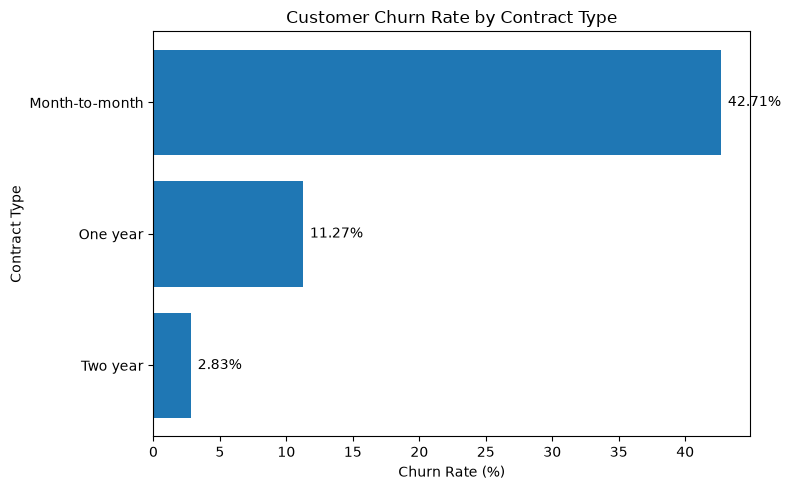

In [43]:

import matplotlib.pyplot as plt

plot_data = contract_churn.sort_values(
    "churn_rate_percent",
    ascending=True
)

plt.figure(figsize=(8, 5))

plt.barh(
    plot_data["Contract"].astype(str),
    plot_data["churn_rate_percent"]
)

plt.xlabel("Churn Rate (%)")
plt.ylabel("Contract Type")
plt.title("Customer Churn Rate by Contract Type")

for position, value in enumerate(plot_data["churn_rate_percent"]):
    plt.text(position * 0 + value + 0.5, position, f"{value:.2f}%", va="center")

plt.tight_layout()
plt.show()


Key finding: Month-to-month customers have a much higher churn rate than customers on longer-term contracts.
1. Month-to-month churn is approximately 3.8 times the one-year contract churn rate.
2. It is approximately 15.1 times the two-year contract churn rate.
3. Only 2.83% of two-year contract customers churned, compared with 42.71% of month-to-month customers.

Compare churn by payment method

In [44]:

payment_churn = pd.read_sql(
    text("""
        SELECT
            "PaymentMethod",
            COUNT(*) AS total_customers,
            SUM(
                CASE
                    WHEN "Churn" = 'Yes' THEN 1
                    ELSE 0
                END
            ) AS churned_customers,
            ROUND(100.0 * SUM(
                    CASE
                        WHEN "Churn" = 'Yes' THEN 1
                        ELSE 0
                    END
                ) / COUNT(*),2) AS churn_rate_percent
        FROM customers
        GROUP BY "PaymentMethod"
        ORDER BY churn_rate_percent DESC;
    """),
    con=engine
)

display(payment_churn)


,PaymentMethod,total_customers,churned_customers,churn_rate_percent
0,Electronic check,2365,1071,45.29
1,Mailed check,1612,308,19.11
2,Bank transfer (automatic),1544,258,16.71
3,Credit card (automatic),1522,232,15.24


interpretation
1. Electronic check customers have the highest churn rate: 45.29% - roughly 45 out of every 100 customers using this payment method have churned.
2. Credit card customers have the lowest churn rate: 15.24%.
3. The electronic check churn rate is almost 3 x credit card churn rate.

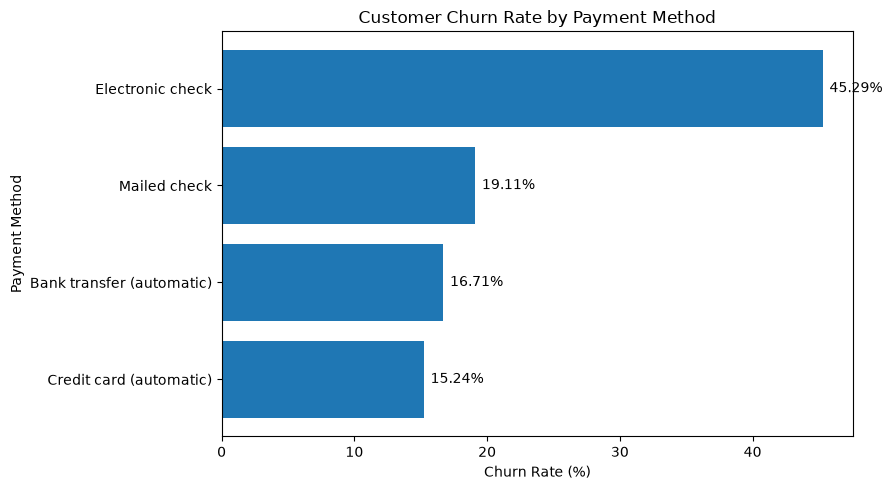

In [45]:

import matplotlib.pyplot as plt

# Sort payment methods from highest to lowest churn rate
plot_data = payment_churn.sort_values(
    "churn_rate_percent",
    ascending=True
)

# Create the chart
plt.figure(figsize=(9, 5))

plt.barh(
    plot_data["PaymentMethod"].astype(str),
    plot_data["churn_rate_percent"]
)

# Add titles and labels
plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Payment Method")

# Display the churn rate at the end of each bar
for position, value in enumerate(plot_data["churn_rate_percent"]):
    plt.text(
        value + 0.5,
        position,
        f"{value:.2f}%",
        va="center"
    )

plt.tight_layout()
plt.show()


investigating churn by multiple factors (tenure, contract type, internet service, and payment method)

In [46]:

contract_internet_churn = pd.read_sql_query(
    """
    SELECT
        "Contract",
        "InternetService",
        COUNT(*) AS total_customers,
        SUM(
            CASE
                WHEN "Churn" = 'Yes' THEN 1
                ELSE 0
            END
        ) AS churned_customers,
        ROUND(100.0 * SUM(
                CASE
                    WHEN "Churn" = 'Yes' THEN 1
                    ELSE 0
                END
            ) / COUNT(*),2) AS churn_rate_percent
    FROM customers
    GROUP BY "Contract", "InternetService"
    ORDER BY churn_rate_percent DESC;
    """,
    con=engine
)

display(contract_internet_churn)


,Contract,InternetService,total_customers,churned_customers,churn_rate_percent
0,Month-to-month,Fiber optic,2128,1162,54.61
1,Month-to-month,DSL,1223,394,32.22
2,One year,Fiber optic,539,104,19.29
3,Month-to-month,No,524,99,18.89
4,One year,DSL,570,53,9.30
5,Two year,Fiber optic,429,31,7.23
6,One year,No,364,9,2.47
7,Two year,DSL,628,12,1.91
8,Two year,No,638,5,0.78


observations:
1. Month-to-month fiber-optic customers have the highest churn rate: 54.61%, -> more than half of this group churned.
2. Month-to-month DSL customers also have substantial churn: 32.22%.
3. Longer contracts are associated with lower churn across all three internet-service categories in your

Visualizing the combined analysis

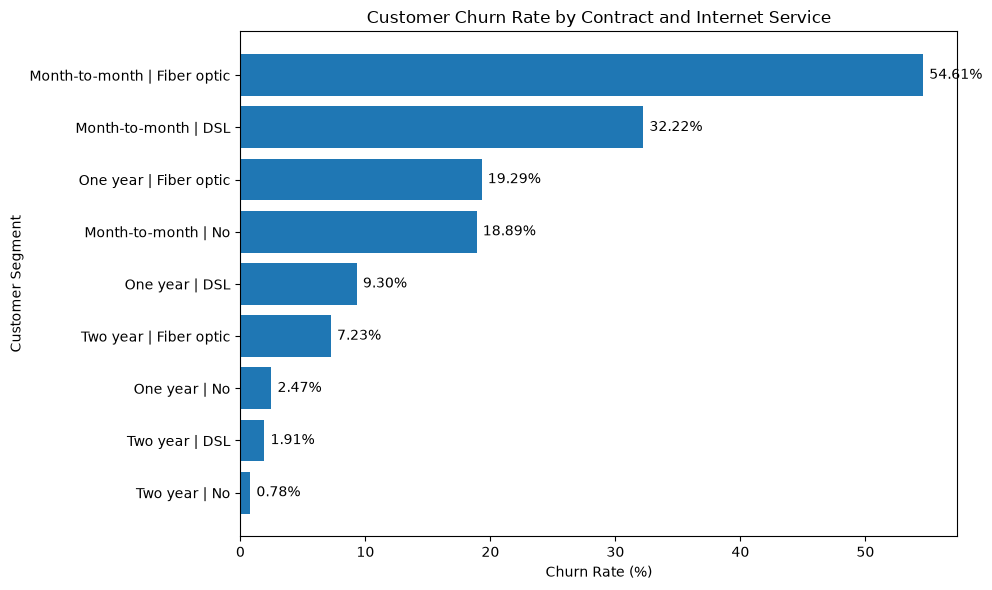

In [47]:

import matplotlib.pyplot as plt

# Create a copy sorted by churn rate
plot_data = contract_internet_churn.sort_values(
    "churn_rate_percent",
    ascending=True
).copy()

# Combine contract and internet service into readable labels
plot_data["customer_segment"] = (
    plot_data["Contract"].astype(str)
    + " | "
    + plot_data["InternetService"].astype(str)
)

# Create the horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["customer_segment"],
    plot_data["churn_rate_percent"]
)

# Add chart title and axis labels
plt.title("Customer Churn Rate by Contract and Internet Service")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Customer Segment")

# Add percentage labels to the bars
for position, value in enumerate(plot_data["churn_rate_percent"]):
    plt.text(
        value + 0.5,
        position,
        f"{value:.2f}%",
        va="center"
    )

plt.tight_layout()
plt.show()


Key Finding: Contract Type and Internet Service

The combined analysis identifies month-to-month customers using fiber-optic internet as the highest-churn segment, with a churn rate of 54.61% (1,162 of 2,128 customers). Month-to-month DSL customers also show elevated churn at 32.22%.

In contrast, customers with two-year contracts have lower churn rates across all three internet-service categories in this dataset. The lowest rate is 0.78% among customers with two-year contracts and no internet service.

Business recommendation:
Investigate the reasons for high churn among month-to-month fiber-optic customers. Review pricing, service quality, customer complaints and onboarding experience before deciding which retention measures to implement.

Limitation:
These results describe associations, not causation. Further analysis is needed to determine whether the observed differences remain after accounting for other customer characteristics.

Analyze monthly charges by churn status

In [48]:

charges_analysis = pd.read_sql_query(
    """
    SELECT
        "Churn",
        COUNT(*) AS total_customers,
        ROUND(AVG("MonthlyCharges")::numeric, 2)
            AS average_monthly_charges,
        ROUND(MIN("MonthlyCharges")::numeric, 2)
            AS minimum_monthly_charges,
        ROUND(MAX("MonthlyCharges")::numeric, 2)
            AS maximum_monthly_charges
    FROM customers
    GROUP BY "Churn"
    ORDER BY "Churn";
    """,
    con=engine
)

display(charges_analysis)


,Churn,total_customers,average_monthly_charges,minimum_monthly_charges,maximum_monthly_charges
0,No,5174,61.27,18.25,118.75
1,Yes,1869,74.44,18.85,118.35


findings
1. Higher average charges among churned customers: Customers who left paid an average of 74.44 per month, compared with 61.27 among customers who stayed.
2. The difference is 13.17 per month. This suggests a possible relationship between monthly charges and churn.
3. Important limitation: These averages alone do not establish that higher charges cause customers to leave. Other factors, such as contract type and internet service, may also be associated with churn.

Visualize monthly charges by churn status

In [49]:
#Retriving data
charges_data = pd.read_sql_query(
    """
    SELECT
        "Churn",
        "MonthlyCharges"
    FROM customers
    """,
    con=engine
)

display(charges_data.head())

,Churn,MonthlyCharges
0,No,29.85
1,No,56.95
2,Yes,53.85
3,No,42.30
4,Yes,70.70


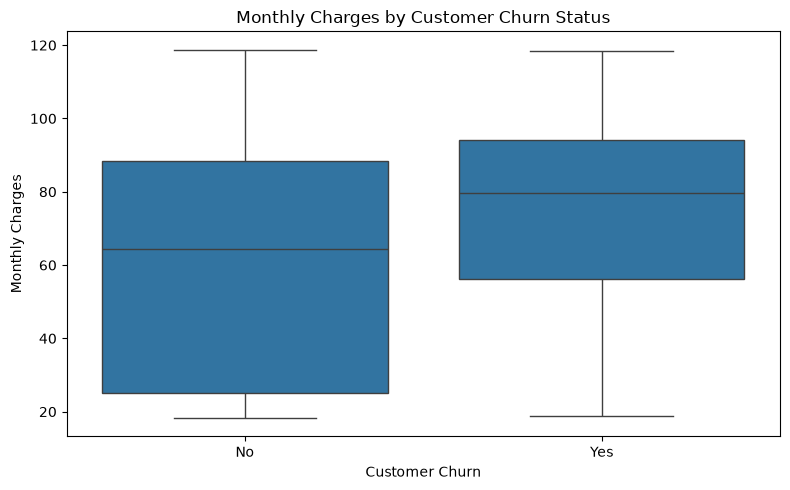

In [50]:
# creating box plot
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=charges_data,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Customer Churn Status")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

from chart
                            stayed(yes)      churned(nO)
median monthly charges          65                 82       
Q1                              25                 58
Q3                              89                 97

- Customers who churned (Yes): Their median monthly charge is approximately 80.
- Customers who stayed (No): Their median monthly charge is approximately 65.
- Distribution: 
The middle 50% of monthly charges for customers who churned appears concentrated at higher prices than for customers who stayed.
- Overlap:
 Both groups contain customers paying low and high monthly charges, so monthly charges alone cannot explain churn.